# 01 · Exploratory Data Analysis: Bank Customer Churn

Goal: understand the data, find what relates to churn (`Exited`), and check for leakage before any modelling. Column definitions come from `src/config.py`, so this notebook and the pipeline never disagree.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from src import config
from src.preprocess import load_raw, add_age_band
sns.set_theme(style='whitegrid')
df = load_raw()
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,1,2,DIAMOND,464
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,1,3,DIAMOND,456
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,1,3,DIAMOND,377
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,0,5,GOLD,350
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,0,5,GOLD,425


## 1. Data quality

In [2]:
print('shape:', df.shape)
print('missing values:', int(df.isna().sum().sum()))
print('duplicate rows:', int(df.duplicated().sum()), '| duplicate CustomerId:', int(df.CustomerId.duplicated().sum()))
df.describe().T

shape: (10000, 18)
missing values: 0
duplicate rows: 0 | duplicate CustomerId: 0


,count,mean,std,min,25%,50%,75%,max
RowNumber,10000.0,5.000500e+03,2886.895680,1.00,2500.75,5.000500e+03,7.500250e+03,10000.00
CustomerId,10000.0,1.569094e+07,71936.186123,15565701.00,15628528.25,1.569074e+07,1.575323e+07,15815690.00
CreditScore,10000.0,6.505288e+02,96.653299,350.00,584.00,6.520000e+02,7.180000e+02,850.00
Age,10000.0,3.892180e+01,10.487806,18.00,32.00,3.700000e+01,4.400000e+01,92.00
Tenure,10000.0,5.012800e+00,2.892174,0.00,3.00,5.000000e+00,7.000000e+00,10.00
Balance,10000.0,7.648589e+04,62397.405202,0.00,0.00,9.719854e+04,1.276442e+05,250898.09
NumOfProducts,10000.0,1.530200e+00,0.581654,1.00,1.00,1.000000e+00,2.000000e+00,4.00
HasCrCard,10000.0,7.055000e-01,0.455840,0.00,0.00,1.000000e+00,1.000000e+00,1.00
IsActiveMember,10000.0,5.151000e-01,0.499797,0.00,0.00,1.000000e+00,1.000000e+00,1.00
EstimatedSalary,10000.0,1.000902e+05,57510.492818,11.58,51002.11,1.001939e+05,1.493882e+05,199992.48


## 2. Target balance
About 1 in 5 customers left. Accuracy is therefore misleading (predicting 'stayed' for everyone scores ~80%), so we use ROC-AUC, PR-AUC and recall.

In [3]:
df[config.TARGET].value_counts(normalize=True).rename('share')

Exited
0    0.7962
1    0.2038
Name: share, dtype: float64

## 3. Leakage check: `Complain`

In [4]:
pd.crosstab(df.Complain, df.Exited, margins=True)

Exited,0,1,All
Complain,,,
0,7952,4,7956
1,10,2034,2044
All,7962,2038,10000


Only 14 of 10,000 customers break the rule *complained ⇔ exited*. A complaint is almost certainly logged around the exit itself, so it would not be known in time to act. **`Complain` is dropped** (see `config.LEAKY_COLS`).

## 4. Numeric features vs churn

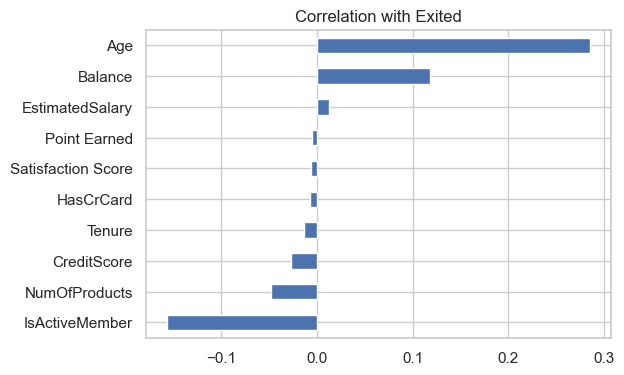

In [5]:
num = df[config.NUMERIC_COLS + [config.TARGET]]
num.corr()[config.TARGET].drop(config.TARGET).sort_values().plot.barh(figsize=(6,4), title='Correlation with Exited');

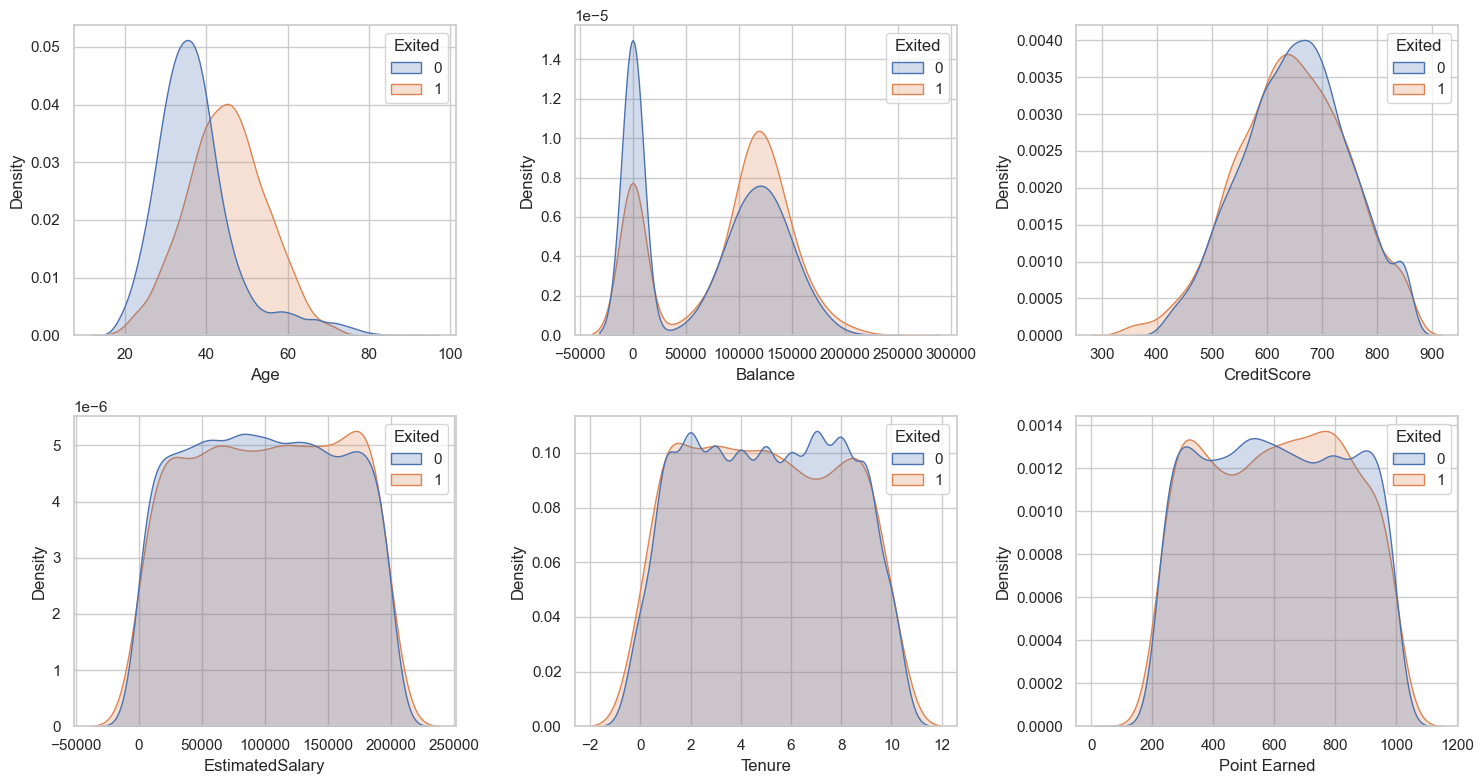

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, ['Age', 'Balance', 'CreditScore', 'EstimatedSalary', 'Tenure', 'Point Earned']):
    sns.kdeplot(data=df, x=col, hue='Exited', common_norm=False, fill=True, ax=ax)
plt.tight_layout()

**Age** is the clearest separator: churners are older (peak 45-55). Balance shows a spike at 0 (36% of customers), which is a real feature, not missing data. Salary, credit score, tenure and points barely differ between groups.

## 5. Categorical features vs churn rate

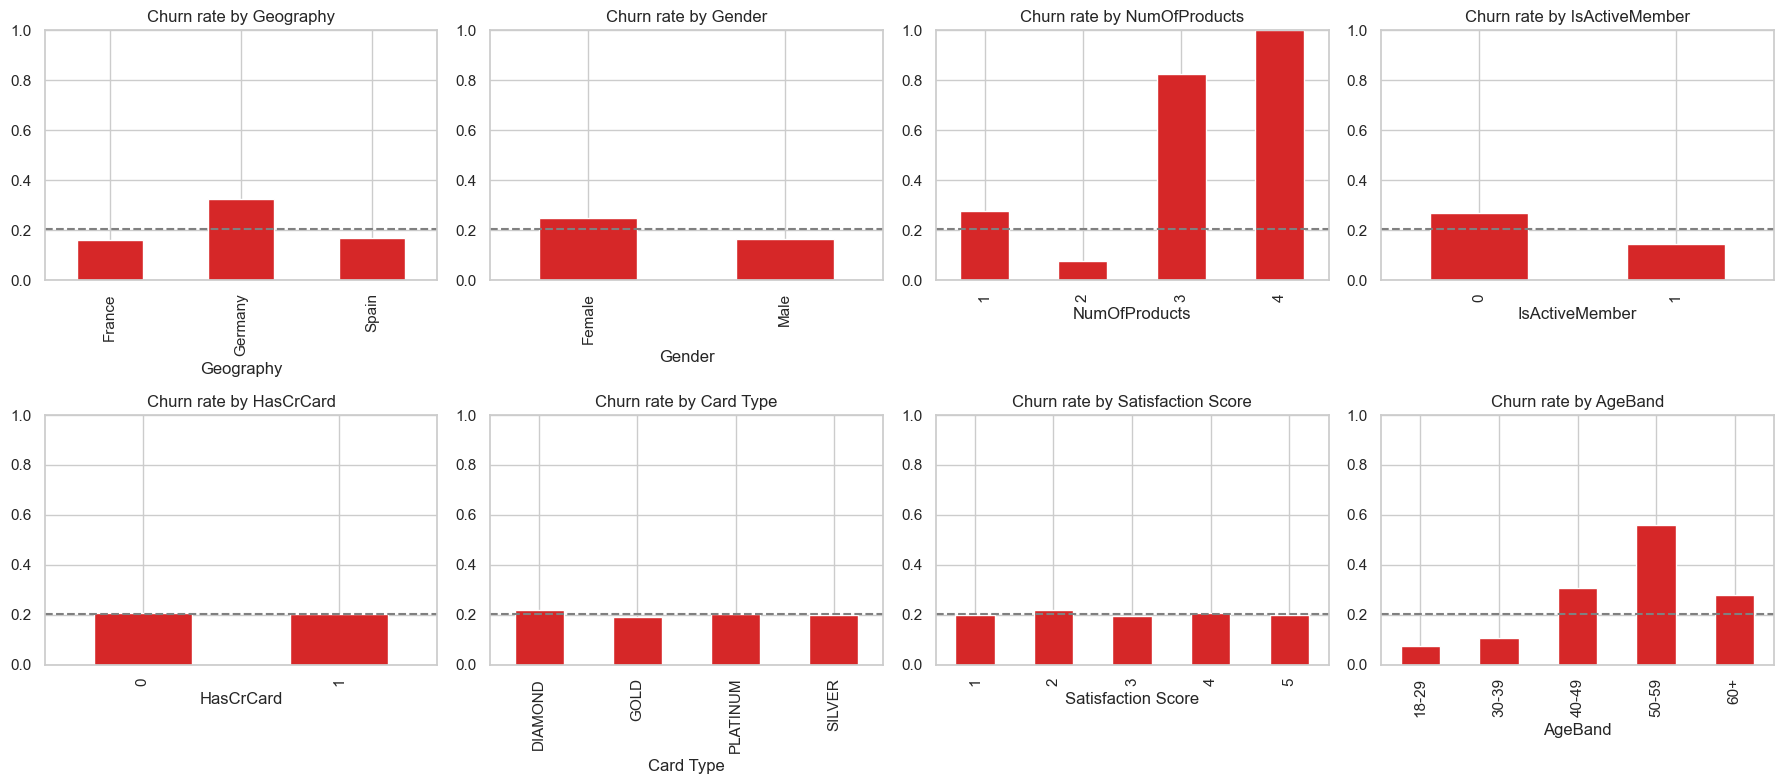

In [7]:
df['AgeBand'] = add_age_band(df)
cats = ['Geography', 'Gender', 'NumOfProducts', 'IsActiveMember', 'HasCrCard', 'Card Type', 'Satisfaction Score', 'AgeBand']
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, cats):
    r = df.groupby(col, observed=True)[config.TARGET].mean()
    r.plot.bar(ax=ax, color='#D62728', title=f'Churn rate by {col}')
    ax.axhline(df[config.TARGET].mean(), ls='--', c='grey'); ax.set_ylim(0, 1)
plt.tight_layout()

Findings:
- **NumOfProducts** is strongly non-linear: 2 products ≈ 8% churn, 3 ≈ 83%, 4 = 100%. Tree models handle this; for the linear model we add a categorical `ProductsCat` feature.
- **Germany** churns at about 2× France and Spain.
- **Inactive members** churn at about 2× active ones.
- **Women** churn more than men (25% vs 17%). Gender is kept as a feature but audited for fairness.
- `Card Type`, `Satisfaction Score` and `HasCrCard` show almost no difference. They are kept, as agreed, and their (low) contribution is visible in SHAP.

## 6. Interactions

In [8]:
pd.pivot_table(df, values='Exited', index='AgeBand', columns='IsActiveMember', observed=True).style.format('{:.0%}').background_gradient(cmap='Reds')

IsActiveMember,0,1
AgeBand,,
18-29,10%,5%
30-39,14%,8%
40-49,38%,23%
50-59,81%,37%
60+,86%,13%


In [9]:
pd.pivot_table(df, values='Exited', index='Geography', columns='NumOfProducts').style.format('{:.0%}').background_gradient(cmap='Reds')

NumOfProducts,1,2,3,4
Geography,,,,
France,22%,6%,79%,100%
Germany,43%,12%,90%,100%
Spain,22%,7%,79%,100%


Older inactive customers are the highest-risk segment. This motivates the `AgeXActive` engineered feature. Engineered features (`ZeroBalance`, `BalanceToSalary`, `AgeXActive`, `ProductsCat`) are tested against raw features in `src/train.py` and logged in `experiments/log.csv`.

**Conclusion:** the data has real signal (go/no-go passed). Proceed to `python -m src.train`.